## **실습 개요**

여러분은 스타트업 투자를 검토하는 벤처캐피탈(VC)의 데이터 분석팀에 합류했습니다. <br>
투자 심사역들은 여러 스타트업의 지출 내역(연구개발비, 관리비, 마케팅비)과 본사 소재지 정보를 바탕으로,<br>
**스타트업의 예상 순이익(Profit)을 예측**하는 모델을 만들어 투자 의사결정에 참고하려고 합니다.

재무팀에서 취합해 넘겨준 데이터에는 입력 실수로 인한 이상치, 결측치, 중복 입력된 행이 섞여 있습니다. <br>
이 데이터를 정제하고 **다중 선형 회귀(Multiple Linear Regression)** 모델을 학습시켜, 새로운 스타트업의 예상 순이익을 예측해봅시다.

## **데이터셋 설명**

여러 스타트업들의 지출 항목별 비용과 순이익에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| R&D Spend | 연구개발(R&D)에 지출한 비용 (달러) |
| Administration | 관리 및 운영에 지출한 비용 (달러) |
| Marketing Spend | 마케팅에 지출한 비용 (달러) |
| State | 스타트업 본사가 위치한 주(州) (New York / California / Florida) |
| Profit | **[target]** 스타트업의 순이익 (달러) |

## **데이터셋 URL**

url :https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv

## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지x
plt.rcParams['axes.unicode_minus'] = False

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,24967.87,141561.98,13309.33,California,56387.42
1,80957.01,171801.30,0.00,California,85070.65
2,59229.85,NaN,35914.66,Florida,57781.05
3,96902.98,120396.70,113669.24,Florida,102467.54
4,NaN,125940.06,149606.63,Florida,73350.78


**Q1. 데이터의 shape(행, 열 개수)을 확인하세요.**

In [4]:
# code here
df.shape

(995, 5)

**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**


In [5]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        954 non-null    float64
 1   Administration   935 non-null    float64
 2   Marketing Spend  946 non-null    float64
 3   State            995 non-null    str    
 4   Profit           995 non-null    float64
dtypes: float64(4), str(1)
memory usage: 39.0 KB


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [6]:
# code here
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,954.000000,935.000000,946.000000,995.000000
mean,79363.521446,122429.422820,109843.986649,84893.717839
std,45844.125872,27825.971717,74558.783452,35415.447535
min,-61979.136882,-149983.611198,-39197.266737,8236.520000
25%,46915.627500,104686.440000,57413.237500,59699.580000
50%,72382.655000,123022.140000,105407.225000,80343.630000
75%,104200.502500,140872.580000,156681.112500,106108.385000
max,412182.953748,183000.000000,639768.992471,184672.110000


## **2. 데이터 분석하기**
데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**

```
from google.colab import files
files.download("submission.csv")
```


### **2-1. 데이터 탐색**


**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- State별 평균 Profit을 소수점 2자리까지 구하세요.

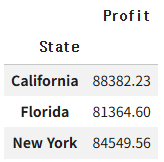

In [7]:
# code here
q1 = df.groupby("State")["Profit"].mean().round(2)
q1.to_csv("ML01.csv")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- R&D Spend 기준 상위 10개 스타트업의 평균 Profit을 소수점 2자리까지 구하세요.
- Marketing Spend가 0 이하인 스타트업의 개수를 구하세요.
- New York에 존재하는 기업의 비율을 백분률로, 소수점 2자리 까지 구하세요.

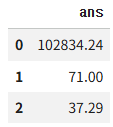

In [8]:
ans = []

In [9]:
# code here

q2_1 = df.sort_values("R&D Spend",ascending=False).head(10)["Profit"].mean().round(2)
q2_2 = len(df[df["Marketing Spend"] <= 0])
q2_3 = round(((len(df[df["State"] == "New York"]) / len(df)) * 100),2)
# (df[df["State"]] == "New York"].mean() * 100).round(2)
# ans.append(q2_1)
# ans.append(q2_2)
# ans.append(q2_3)


In [10]:
import pandas as pd
sub = pd.DataFrame(ans, columns=["ans"])


In [11]:
sub.to_csv("ML02.csv", index=False)

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 데이터에 존재하는 State별 개수의 분포와 R&D에 활용하는 평균 비용을 소수점 2자리까지 구하세요.

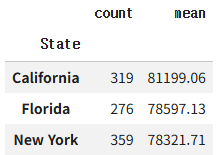

In [12]:
# code here
q3 = df.groupby("State")["R&D Spend"].agg(["count", "mean"]).reset_index().round(2)
q3.to_csv("ML03.csv", index=False)

### **2-2. 데이터 시각화**

**Q1. Profit의 분포를 히스토그램으로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

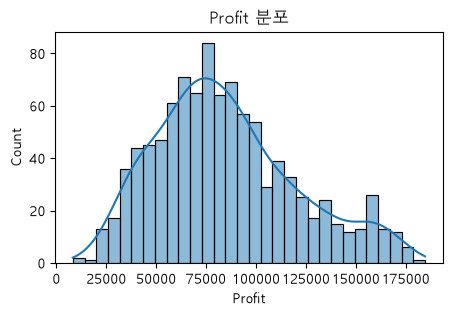

In [13]:
# code here
import seaborn as sns

plt.figure(figsize=(5,3))
plt.title("Profit 분포")
sns.histplot(df["Profit"], kde = True, bins = 30)
plt.show()

**Q2. R&D Spend와 Profit의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

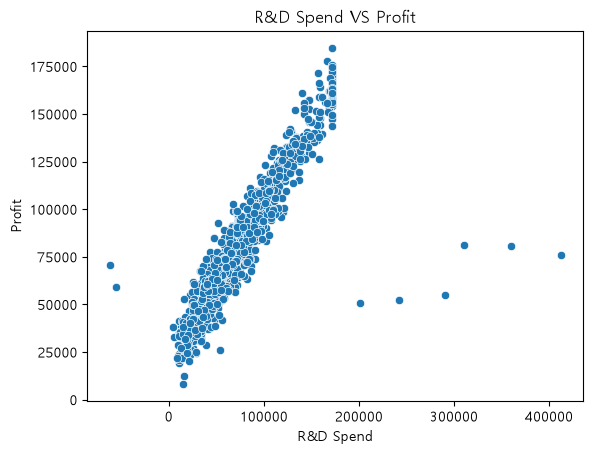

In [14]:
# code here
plt.title("R&D Spend VS Profit")
sns.scatterplot(df, x = "R&D Spend", y = "Profit")
plt.show()

**Q3. R&D Spend와 Marketing Spend의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

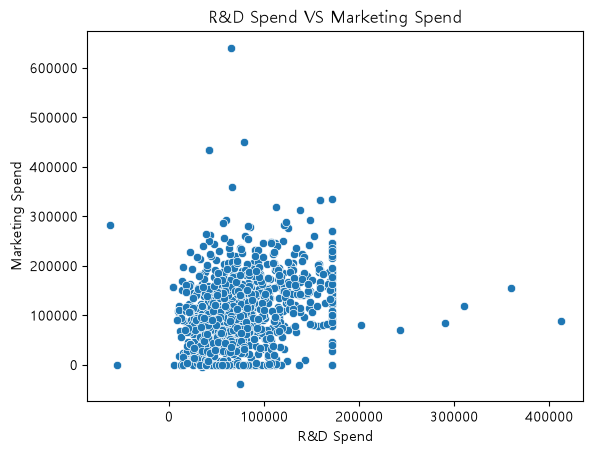

In [15]:
# code here
plt.title("R&D Spend VS Marketing Spend")
sns.scatterplot(df, x = "R&D Spend", y = "Marketing Spend")
plt.show()

**Q4. State별 Profit을 박스플롯(box plot)으로 비교하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

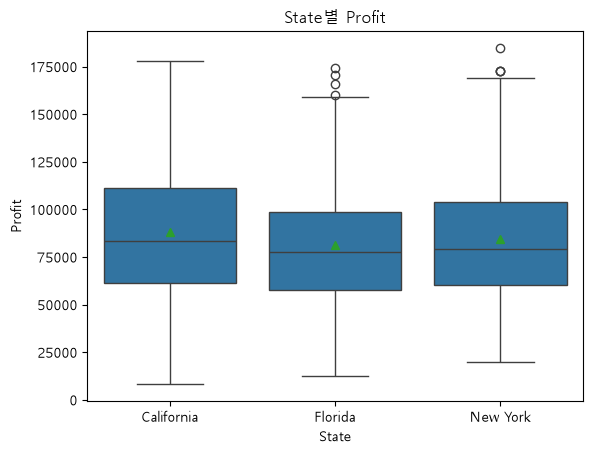

In [16]:
# code here
plt.title("State별 Profit")
sns.boxplot(df, x="State", y ="Profit", showmeans="^")
plt.show()

**Q5. Marketing Spend를 박스플롯으로 확인하세요.**

그리고 이 그래프로서 알 수 있는 정보를 코드 아래에 적어주세요.

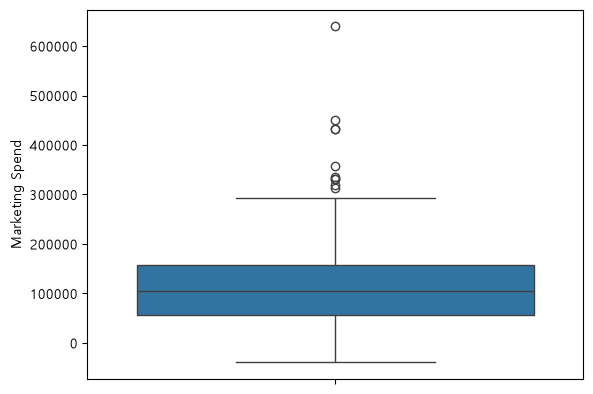

In [17]:
# code here
sns.boxplot(df["Marketing Spend"])
plt.show()

## **3. 데이터 전처리하기**

In [18]:
# 데이터를 전처리하다 망가트리면 여기서부터 재시작!
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/startups.csv")
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,24967.87,141561.98,13309.33,California,56387.42
1,80957.01,171801.30,0.00,California,85070.65
2,59229.85,NaN,35914.66,Florida,57781.05
3,96902.98,120396.70,113669.24,Florida,102467.54
4,NaN,125940.06,149606.63,Florida,73350.78


### **3-1. 이상치 처리하기 1**

이상치를 해결하는 방법은 2가지가 있습니다.
<br>그 중 첫번째는 그냥 삭제를 해버리는 것입니다.

**Q1. 애초에 말도 안되는 데이터는 제거를 해봅시다.**
- R&D Spend, Administration, Marketing Spend는 음수가 될 수 없습니다. (지출 비용).

일반적으로는, 데이터 학습 및 테스트에 "안 쓰일 데이터"는 추가적인 전처리 과정 전에 먼저 제거를 합니다.

**R&D Spend, Administration, 그리고 Marketing Spend중 하나라도 음수인 행들의 개수를 세어 봅시다.**

In [19]:
# code here
df[(df["R&D Spend"] < 0) | (df["Administration"] < 0) | (df["Marketing Spend"] < 0)].count()

R&D Spend          6
Administration     6
Marketing Spend    6
State              6
Profit             6
dtype: int64

**Q2. 위에 해당하는 행들을 모두 삭제해 봅시다.**

In [20]:
# code here
minus_row = (df["R&D Spend"] < 0) | (df["Administration"] < 0) | (df["Marketing Spend"] < 0)
df_minus = df[~minus_row] # 1차 이상치 처리를 진행한 df


**Q3. 남아있는 음수 값이 없는지 다시 확인해보세요.**

In [21]:
# code here
df_minus[(df_minus["R&D Spend"] < 0) | (df_minus["Administration"] < 0) | (df_minus["Marketing Spend"] < 0)].count()



R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

### **3-2. 데이터 분리하기**

**Q1. Profit을 target으로 하여 train과 테스트 데이터를 분리합니다.**
- 비율 : 7(학습) : 3(테스트)
- 재현성을 위해 random_state = 101로 설정합니다.

In [22]:
from sklearn.model_selection import train_test_split 

# input: Profit만 제외한 모든 열들
X = df_minus.drop("Profit", axis = 1) # axis = 0 행, axis = 1 열
    
# target
y = df_minus["Profit"]

In [23]:
# code here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### **3-3. 결측치 처리하기**

Data Leakage를 방지하기 위해, 모든 학습과 테스트에 전처리되어 사용될 데이터는 학습, 테스트 데이터 분리 이후 진행합니다.

결측치를 채우는 방법은 크게 2가지가 있습니다.
- **평균(Mean)**: 이상치가 없고 데이터가 좌우 대칭(정규분포)일 때 적합합니다.
- **중위수(Median)** : 데이터에 이상치가 있거나, 한쪽으로 치우친 데이터일 때 안전합니다.
- **최빈값(Mode)**: 데이터가 카테코리이면

**Q1. train 데이터의 결측치 개수를 확인합니다.**

In [24]:
# code here
X_train.isnull().sum()

R&D Spend          27
Administration     45
Marketing Spend    32
State               0
dtype: int64

**Q2. R&D Spend, Administration, Marketing Spend의 결측치를 train 데이터의 중앙값(median)으로 대체하세요.**

이때, test 데이터에도 동일한(train 기준) 값을 사용하세요



In [25]:
# code here
# 1. 컬럼중에서 int64, float로만 구성되어 있는 것만 가져옴
numeric_cols = X_train.select_dtypes(include = "number").columns
# 2. 각 채워야하는 열들에 대해, 중앙값으로 채우기로 했으니, 중앙값을 구해보자
fill_values = X_train[numeric_cols].median()  # 각 열을 이 값으로 채울 것이다.
# 3. 채우기
X_train[numeric_cols] = X_train[numeric_cols].fillna(fill_values)

**Q3. 다시 한번 train 데이터의 결측치 개수를 확인합니다.**

In [26]:
# code here
X_train.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
dtype: int64

In [27]:
X_test[numeric_cols] = X_test[numeric_cols].fillna(fill_values)
X_test.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
dtype: int64

### **3-4. 이상치 처리하기 2**

이상치를 해결하는 두번째 방법은, clipping (capping, winsorizing)입니다.

**Q1. IQR을 통해 각 column에 outlier가 몇 개씩이나 있는지를 확인해보세요.**

In [28]:
# code here
# outlier = 이상치
# 몇개가 있느냐? 좌측 whisker, 우측 whisker를 벗어나는 데이터의 개수
# 좌측 whisker : 25% * 1.5배까지 유예
# 우측 whisker : 75% * 1.5배까지 유예


# data: dataframe
# column: 이 dataframe의 어떤 열에 대해서 whisker를 찾으려고 하는지
def find_whiskers(data, column):
    #1. 25%, 75% quantile 찾기
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    #2. Inter Quntail Range구하기
    iqr = Q3 - Q1
    #3. 좌측 whisker와 우측 whisker를 구하기
    lower = Q1 - (1.5 * iqr)
    upper = Q3 + (1.5 * iqr)

    return (lower,upper)

In [29]:
# lower와 upper whisker를 dataframe 각각의 column마다 찾아낼 수 있음
# column에서 이 lower보다 작거나, upper보다 큰 값 -> 이상치

numeric_cols = X_train.select_dtypes(include = "number").columns

d = {} #key: 컬럼명, value : 튜플로 (lower, upper) <-한계치 이거보다 높거나 작은거는 채움

for c in numeric_cols:               #하나씩 열에 접근
    # lower, upper whisker를 만들어준 함수로 찾아옴
    lower, upper = find_whiskers(X_train, c)
    d[c] = (lower, upper)
    count = ((X_train[c] < lower) | (X_train[c] > upper)).sum() #lower보다 작거나 upper보다 큰 값 개수 세기
    print(f"{c} {count}개")
    # print(f"{c} : {lower}, {upper}")


R&D Spend 5개
Administration 4개
Marketing Spend 9개


**Q2. IQR 기준을 이용해, 수치형 컬럼의 값을 [Q1 - 1.5 * IQR ~ Q3 + 1.5 * IQR] 범위로 clipping(capping)하세요.**
- 이상치를 제거(행 삭제)하지 않고 범위 내로 눌러주는(capping) 방식을 사용하여 데이터 손실 없이 극단값의 영향을 줄입니다.
- train 기준의 lower/upper bound를 test에도 동일하게 적용하세요.

In [30]:
# code here
# clip()
for c in numeric_cols:
    # 1. 우리가 찾아둔 lower, upper whisker를 가져옴
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower,upper) # lower 보다 작은거는 lower, upper보다 작은 거는 upper
    # test_data에도 이상치가 있음. -> train 데이터의 lower와 upper whisker로 clipping
    X_test[c] = X_test[c].clip(lower, upper)

**Q3. 각 컬럼에 이상치가 아직 존재하는지 확인합니다.**

In [31]:
# code here
for c in numeric_cols:
    # 다시 find_whisker를 하면 또 이상치가 생길 수 있으므로.
    count = ((X_train[c] < d[c][0]) | (X_train[c] > d[c][1])).sum()
    print(f"{c} : {count}개")

R&D Spend : 0개
Administration : 0개
Marketing Spend : 0개


**Q4. 캡핑 처리 검증을 위해 boxplot을 다시 한번 그려 봅시다.**

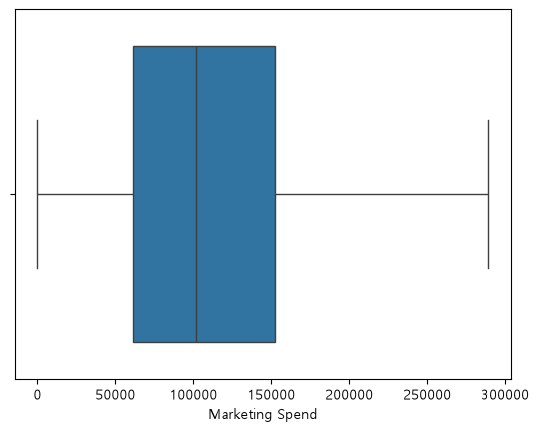

In [32]:
# code here
import seaborn as sns
# plt.figure(figsize=(5,3))
sns.boxplot(X_train["Marketing Spend"], orient = 'h')
plt.show()

### **3-5. Feature Encoding**

In [33]:
# label encoding
train_copy = X_train.copy()
train_copy

,R&D Spend,Administration,Marketing Spend,State
640,67842.10,124219.66,20981.85,Florida
941,95312.54,113312.86,33814.90,Florida
577,57058.37,140898.69,177682.56,New York
929,158476.09,149272.77,167244.23,Florida
409,109922.32,113881.03,223596.19,New York
...,...,...,...,...
107,108131.46,111672.95,72063.11,New York
274,44888.45,116632.41,32565.01,Florida
866,142021.39,147375.74,101448.46,New York
440,172000.00,85465.73,0.00,New York


In [34]:
# python으로 mapping 하는 방법
def put_label(x):
    if x == "Florida":
        return 0
    elif x == "New York":
        return 1
    else:
        return 2

train_copy["State"] = train_copy["State"].map(put_label)
train_copy


,R&D Spend,Administration,Marketing Spend,State
640,67842.10,124219.66,20981.85,0
941,95312.54,113312.86,33814.90,0
577,57058.37,140898.69,177682.56,1
929,158476.09,149272.77,167244.23,0
409,109922.32,113881.03,223596.19,1
...,...,...,...,...
107,108131.46,111672.95,72063.11,1
274,44888.45,116632.41,32565.01,0
866,142021.39,147375.74,101448.46,1
440,172000.00,85465.73,0.00,1


In [35]:
# 2. sklearn의 label encoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# 1. fit_transform: fit :학습한다
train_copy["State"] = le.fit_transform(train_copy["State"])


# 2. transform() :test data도 인코딩 할때에는 -> transform
# X_test["State"] = le.fit_transform(X_test["State"])

In [36]:
train_copy

,R&D Spend,Administration,Marketing Spend,State
640,67842.10,124219.66,20981.85,0
941,95312.54,113312.86,33814.90,0
577,57058.37,140898.69,177682.56,1
929,158476.09,149272.77,167244.23,0
409,109922.32,113881.03,223596.19,1
...,...,...,...,...
107,108131.46,111672.95,72063.11,1
274,44888.45,116632.41,32565.01,0
866,142021.39,147375.74,101448.46,1
440,172000.00,85465.73,0.00,1


**Q1. State컬럼을 인코딩하세요.**

State는 순서가 없는 3개 범주(New York / California / Florida)를 갖는 명목형(nominal) 변수이므로, One-Hot Encoding을 활용합니다.

먼저 X_train 데이터의 컬럼을 One-Hot Encoding 해보도록 합시다.

In [37]:
# code here
from sklearn.preprocessing import OneHotEncoder

# encoder 객체를 만들기
ohe = OneHotEncoder(sparse_output=False, drop = 'first') # <- ohe 할 때에는 하나의 컬럼은 보통 drop (drop = 'first')


In [38]:
encoded_state = ohe.fit_transform(X_train[["State"]])   # matrix 형태로 넣어야한다.
encoded_state

array([[1., 0.],
       [1., 0.],
       [0., 1.],
       ...,
       [0., 1.],
       [0., 1.],
       [0., 0.]], shape=(692, 2))

In [39]:
ohe.get_feature_names_out()

array(['State_Florida', 'State_New York'], dtype=object)

In [40]:
# 1. X_train에서 State 열을 지워야함.
X_train = X_train.drop("State", axis = 1)

In [41]:
# 2. ohe.get_feature_names_out()와 encoded_state를 기반으로 새로운 dataframe을 만들고,

encoded_state_df = pd.DataFrame(encoded_state, columns = ohe.get_feature_names_out(), index=X_train.index)
encoded_state_df



,State_Florida,State_New York
640,1.0,0.0
941,1.0,0.0
577,0.0,1.0
929,1.0,0.0
409,0.0,1.0
...,...,...
107,0.0,1.0
274,1.0,0.0
866,0.0,1.0
440,0.0,1.0


In [42]:
# 3. 그걸 다시 X_train과 연결

X_train = pd.concat([X_train, encoded_state_df], axis = 1)
# X_train.drop(["State_Florida", "State_New York"], axis = 1)

**Q2. 테스트 데이터의 State 컬럼도 one-hot encoding 해줍니다.**

In [43]:
# code here
# 1. One Hot Encoding
encoded_state_test = ohe.transform(X_test[["State"]])
encoded_state_test

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 0.],
       [1., 0.],
       [0., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [0., 1.],
       [0., 0.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [0., 0.

In [44]:
# test data에서도 State열 정리
X_test = X_test.drop("State", axis = 1)

In [45]:
encoded_state_test_df = pd.DataFrame(encoded_state_test, columns = ohe.get_feature_names_out(), index = X_test.index)
encoded_state_test_df

,State_Florida,State_New York
216,1.0,0.0
335,1.0,0.0
506,1.0,0.0
313,1.0,0.0
89,0.0,0.0
...,...,...
587,0.0,1.0
433,0.0,1.0
701,0.0,0.0
984,0.0,0.0


In [46]:
X_test = pd.concat([X_test, encoded_state_test_df], axis = 1)
X_test

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
216,115092.64,132518.18,173210.77,1.0,0.0
335,145208.30,158947.97,178731.37,1.0,0.0
506,82888.03,118515.29,147923.83,1.0,0.0
313,86651.50,100135.32,0.00,1.0,0.0
89,105981.46,133599.67,172880.68,0.0,0.0
...,...,...,...,...,...
587,29955.07,104608.36,83648.35,0.0,1.0
433,33660.33,162176.04,43970.41,0.0,1.0
701,32521.44,106608.55,0.00,0.0,0.0
984,172000.00,137520.59,177807.92,0.0,0.0


## **4. 모델 학습 및 평가**

### **4-1. 모델 학습**

**Q1. Linear Regression 모델을 만들고, 학습시키세요.**

In [47]:
# code here
from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.76, -0. , 0.03,-4234.33,-1105.63]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['R&D Spend','Administration','Marketing Spend','State_Florida', 'State_New York']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.408e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


### **4-2. 예측**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

예측값은 y_pred 에 저장합니다.

In [ ]:
# code here

y_pred = model.predict(X_test)

[112225.25340195 135095.87052071  87063.59065251  85022.12552366
 109550.4009077   97902.11381012  48964.74538227  95262.80656807
  39706.01848784  65932.15821865  69354.09781117  46520.53646979
  79427.77333611  42277.43650436  60331.7326812   34961.53173734
  92350.27687975  75426.48153417  49037.30690779  80852.08013305
 106933.28214684  49343.90179522  81240.10546141 124720.41463167
  95505.33576759  81561.1623565  152185.86914334  93247.20070851
  90052.85831556 100918.67178989  80939.84910228  75721.70480297
  44946.94455616  76976.98609908 144191.81287738 143077.73546949
 153050.35738373  55014.71560941 101990.13329897 115994.79064532
  67236.21656914 115875.67123022  47683.0048717   68231.59779354
  85902.67590569  46983.25915393  85313.67301818  85127.25079975
  34334.11988166 113271.57817523  74584.9394604   65534.1855891
  60590.56115093  57935.62485685  40939.61444461  55630.36089715
  58231.40343915  44664.3391738   69315.09765532  63069.52438472
  31935.80435172  51514.57

### **4-3. 모델 평가**

**Q1. MSE, RMSE, R2 Score를 이용해 모델 성능을 평가하세요.**

In [53]:
# code here
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

print(f"MAE: {mean_absolute_error(y_test, y_pred)}")
print(f"MSE: {mean_squared_error(y_test, y_pred)}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred)}")
print(f"R2_score: {r2_score(y_test, y_pred)}")

MAE: 8728.698672246357
MSE: 166642679.2938913
RMSE: 12909.015426975495
R2_score: 0.8686739375166164
